In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [18]:
df = pd.read_csv('form_responses.csv')
df.sort_values(by='Timestamp', inplace=True)

In [19]:
df.drop(columns=['Timestamp'], inplace=True)

In [20]:
df.head()

df.sex = df['sex'].replace({'Femmina': 0, 'Maschio': 1})

C:\Users\Gabri\AppData\Local\Temp\ipykernel_19332\2001170994.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.sex = df['sex'].replace({'Femmina': 0, 'Maschio': 1})


In [21]:
df.train_years = df['train_years'].replace({'Meno di 1': 0.5 , 'Più di 10': 11})

In [22]:
df.z2_train_week = df.z2_train_week.fillna(0)
df.fartelk_train_week = df.fartelk_train_week.fillna(0)
df.power_train_week = df.power_train_week.fillna(0)

In [23]:
df.avg_km_week = df['avg_km_week'].replace({'Più di 80': 85})

Creo la colonna per avere i tempi in secondi

In [ ]:
def time_to_seconds(t):
    parts = t.split(':')
    parts = [int(p) for p in parts]
    if len(parts) == 3:
        h, m, s = parts
    elif len(parts) == 2:
        h = 0
        m, s = parts
    else:
        return None
    return h * 3600 + m * 60 + s

# Applica la funzione
df['hm_time_sec'] = df['hm_time'].apply(time_to_seconds)
df['mid_hm_time_sec'] = df['mid_hm_time'].apply(time_to_seconds)

Creo la colonna per avere i tempi in minuti

In [36]:
def time_to_minutes(t):
    parts = t.split(':')
    parts = [int(p) for p in parts]
    if len(parts) == 3:
        h, m, s = parts
    elif len(parts) == 2:
        h = 0
        m, s = parts
    else:
        return None
    return h * 60 + m + s / 60

df['hm_time_min'] = df['hm_time'].apply(time_to_minutes)
df['mid_hm_time_min'] = df['mid_hm_time'].apply(time_to_minutes)

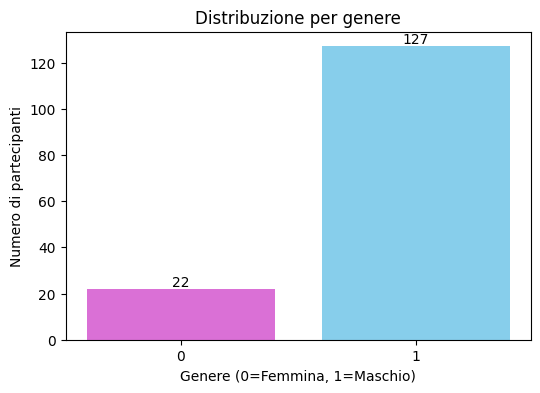

In [24]:
gender_counts = df['sex'].value_counts().sort_index()
plt.figure(figsize=(6, 4))
bars = plt.bar(gender_counts.index.astype(str), gender_counts.values, color=['orchid', 'skyblue'])
plt.xlabel('Genere (0=Femmina, 1=Maschio)')
plt.ylabel('Numero di partecipanti')
plt.title('Distribuzione per genere')

# Aggiungi il numero sopra ogni barra
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height, f'{int(height)}', ha='center', va='bottom')

plt.show()


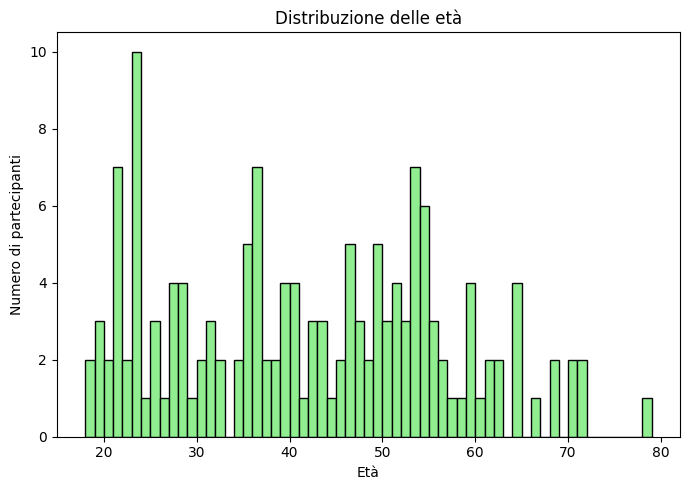

In [25]:
fig, ax = plt.subplots(figsize=(7, 5))

ax.hist(df['age'], bins=range(df['age'].min(), df['age'].max() + 2), color='lightgreen', edgecolor='black')
ax.set_xlabel('Età')
ax.set_ylabel('Numero di partecipanti')
ax.set_title('Distribuzione delle età')

plt.tight_layout()
plt.show()



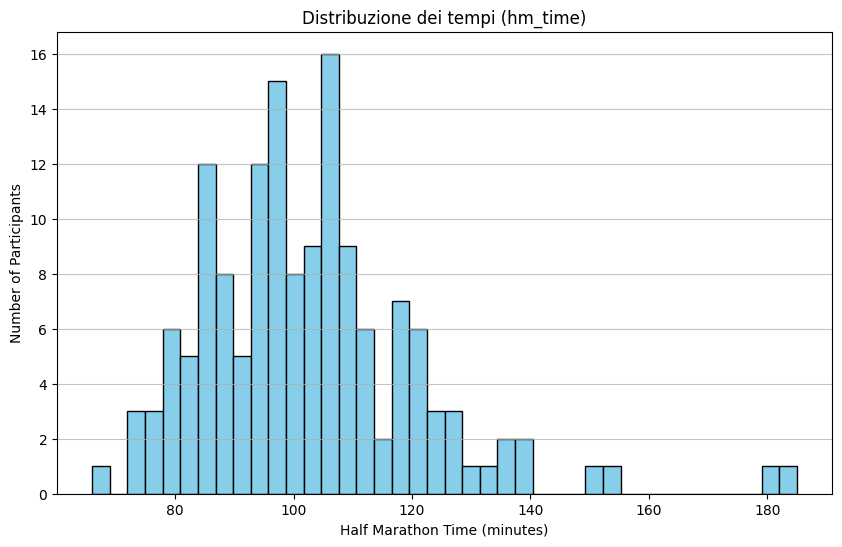

In [26]:
# Convert 'hm_time' to seconds for plotting
hm_time_sec = pd.to_timedelta(df['hm_time']).dt.total_seconds() / 60  # minutes

plt.figure(figsize=(10, 6))
plt.hist(hm_time_sec, bins=40, color='skyblue', edgecolor='black')
plt.xlabel('Half Marathon Time (minutes)')
plt.ylabel('Number of Participants')
plt.title('Distribuzione dei tempi (hm_time)')
plt.grid(axis='y', alpha=0.75)
plt.show()

In [27]:
hm_time_sec = pd.to_timedelta(df['hm_time']).dt.total_seconds() / 60  # minutes

hm_time_sec.mean(), hm_time_sec.std()

(np.float64(102.52774049217003), np.float64(18.64487583587522))

Deviazione standard molto alta, fa intuire che sono state ricevute risposte da runner esperti e da amatori

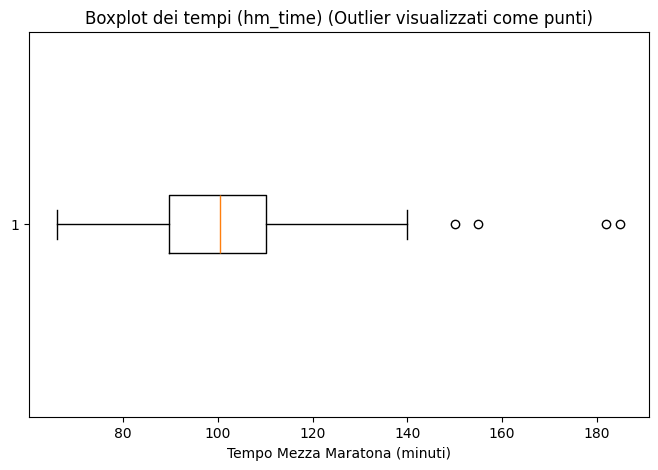

In [28]:
plt.figure(figsize=(8, 5))
plt.boxplot(hm_time_sec, vert=False)
plt.xlabel('Tempo Mezza Maratona (minuti)')
plt.title('Boxplot dei tempi (hm_time) (Outlier visualizzati come punti)')
plt.show()

Infatti qui possiamo notare gli outlier che alzano la deviazione standard

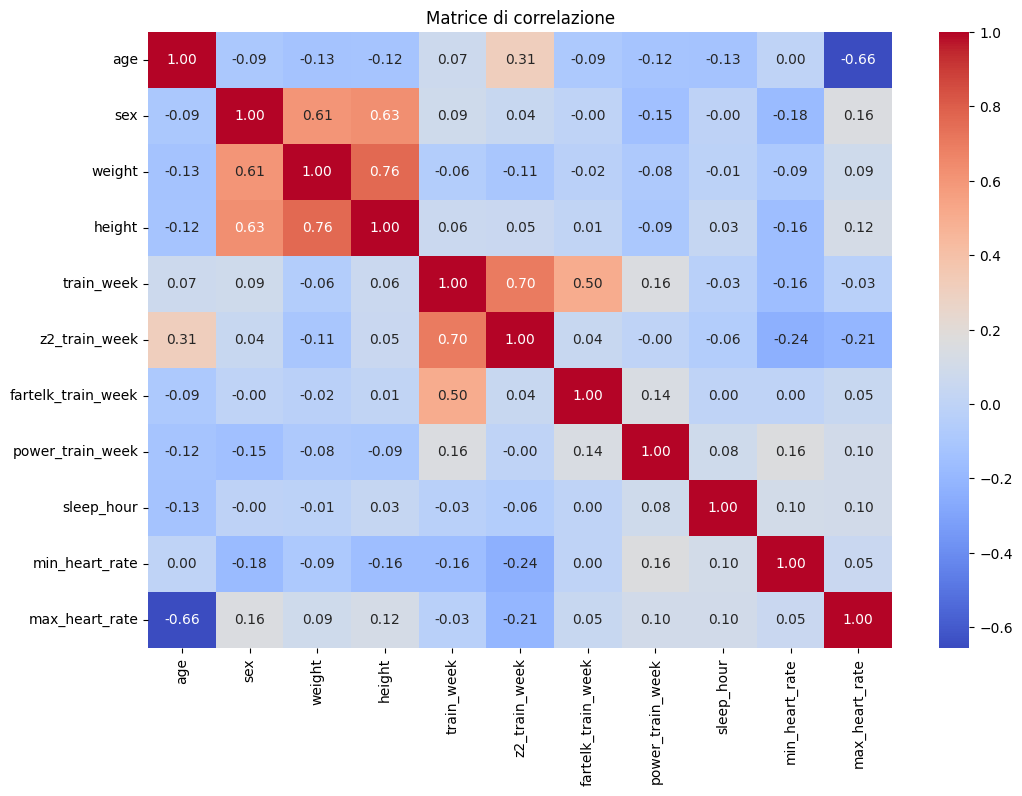

In [31]:

plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", xticklabels=True, yticklabels=True)
plt.title("Matrice di correlazione")
plt.show()


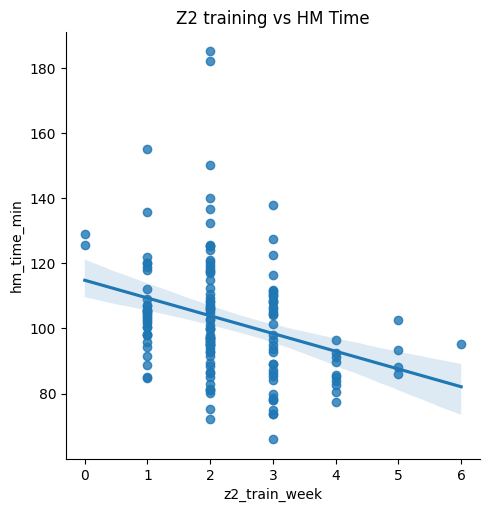

In [37]:
# Scatter plot + regressione
sns.lmplot(data=df, x='z2_train_week', y='hm_time_min')
plt.title("Z2 training vs HM Time")
plt.show()

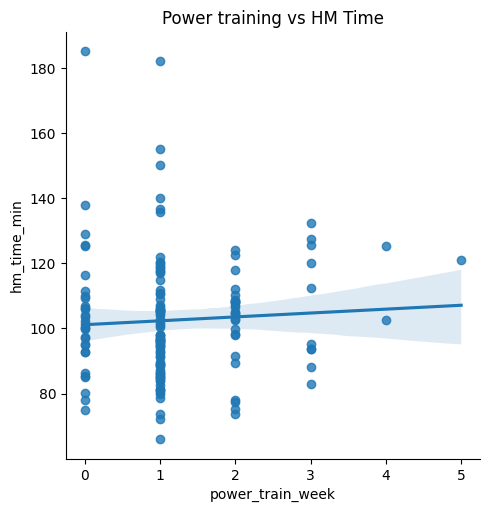

In [38]:
sns.lmplot(data=df, x='power_train_week', y='hm_time_min')
plt.title("Power training vs HM Time")
plt.show()

In [42]:
from scipy.stats import pearsonr

# Correlazioni Pearson
r_z2, _ = pearsonr(df['z2_train_week'], df['hm_time_min'])
r_power, _ = pearsonr(df['power_train_week'], df['hm_time_min'])

print(f"Correlazione Z2-HM Time: {r_z2:.2f}")
print(f"Correlazione Power-HM Time: {r_power:.2f}")

Correlazione Z2-HM Time: -0.30
Correlazione Power-HM Time: 0.06


Z2: La correlazione negativa indica che più allenamenti in zona 2 (Z2) sono associati a tempi finali migliori (più bassi). Il valore -0.30 è una correlazione debole-moderata, ma significativa a livello interpretativo: l'effetto c'è.

Power: La correlazione quasi nulla (0.06) significa che gli allenamenti di potenza non hanno un’associazione chiara con il tempo finale.

In [43]:
r_power10k, _ = pearsonr(df['power_train_week'], df['mid_hm_time_min'])
print(f"Correlazione Power vs Tempo 10km: {r_power10k:.2f}")

Correlazione Power vs Tempo 10km: 0.05
